In [5]:
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [6]:
data = pd.read_csv("NABIL.csv")

price_columns = [
    "open",
    "high",
    "low",
    "close",
    "traded_quantity"
]

required_columns = ["published_date"] + price_columns

missing = set(required_columns) - set(data.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

data["published_date"] = pd.to_datetime(
    data["published_date"]
).dt.normalize()

for column in price_columns:
    data[column] = pd.to_numeric(
        data[column], errors="coerce"
    )

# Check repeated dates before keeping one record.
conflicts = (
    data.groupby("published_date")[price_columns]
    .nunique(dropna=False)
    .gt(1)
    .any(axis=1)
)

if conflicts.any():
    raise ValueError("Some repeated dates have different records.")

data = data.drop_duplicates("published_date")

data = data.dropna(subset=required_columns)

valid_prices = (
    data[["open", "high", "low", "close"]] > 0
).all(axis=1)

data = data[
    valid_prices & (data["traded_quantity"] >= 0)
].copy()

data = data.sort_values("published_date")
data = data.reset_index(drop=True)

print("Trading sessions:", len(data))
print("First date:", data["published_date"].iloc[0].date())
print("Last date:", data["published_date"].iloc[-1].date())

data.head()

Trading sessions: 3503
First date: 2011-05-15
Last date: 2026-09-23


,published_date,open,high,low,close,per_change,traded_quantity,traded_amount,status
0,2011-05-15,1091.0,1155.0,1112.0,1155.0,NaN,38.0,43057.0,0
1,2011-05-16,1155.0,1193.0,1160.0,1193.0,3.29,156.0,183026.0,0
2,2011-05-18,1193.0,1172.0,1150.0,1172.0,-1.76,939.0,1087972.0,0
3,2011-05-19,1172.0,1194.0,1155.0,1194.0,1.88,490.0,573992.0,0
4,2011-05-22,1194.0,1193.0,1178.0,1178.0,-1.34,115.0,135930.0,0


In [7]:
LOOKBACK = 3

# Percentage change from one session to the next.
data["daily_return"] = data["close"].pct_change(
    fill_method=None
)

parameters = [
    "open",
    "high",
    "low",
    "close",
    "traded_quantity",
    "daily_return"
]

features = []
lagged_columns = {}

for parameter in parameters:
    for day in range(1, LOOKBACK + 1):
        column_name = f"{parameter}_{day}"

        lagged_columns[column_name] = data[parameter].shift(day)
        features.append(column_name)

samples = data[["published_date", "close"]].copy()
samples = samples.rename(columns={"close": "actual_close"})

samples = pd.concat(
    [samples, pd.DataFrame(lagged_columns)],
    axis=1
)

samples = samples.replace([np.inf, -np.inf], np.nan)
samples = samples.dropna(subset=features)
samples = samples.reset_index(drop=True)

print("Inputs per example:", len(features))
print("Usable examples:", len(samples))

samples[
    [
        "published_date",
        "actual_close",
        "close_1",
        "open_1",
        "traded_quantity_1"
    ]
].head()

Inputs per example: 18
Usable examples: 3499


,published_date,actual_close,close_1,open_1,traded_quantity_1
0,2011-05-22,1178.0,1194.0,1172.0,490.0
1,2011-05-23,1170.0,1178.0,1194.0,115.0
2,2011-05-24,1150.0,1170.0,1178.0,239.0
3,2011-05-25,1150.0,1150.0,1170.0,282.0
4,2011-05-26,1149.0,1150.0,1150.0,597.0


In [8]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [9]:
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(42)

In [10]:
def predict_date_lstm(date_text):
    try:
        chosen_date = pd.Timestamp(date_text).normalize()
    except (ValueError, TypeError):
        print("Enter a valid date, such as 2026-09-23.")
        return

    if pd.isna(chosen_date):
        print("Please enter a date.")
        return

    selected = samples[
        samples["published_date"] == chosen_date
    ]

    history = samples[
        samples["published_date"] < chosen_date
    ].copy()

    if selected.empty:
        print("Date missing or not enough earlier data.")
        return

    if len(history) < 100:
        print("Choose a later date with at least 100 earlier examples.")
        return

    # Arrange inputs: oldest session first, newest session last.
    ordered_features = []

    for day in range(LOOKBACK, 0, -1):
        for parameter in parameters:
            ordered_features.append(f"{parameter}_{day}")

    number_of_parameters = len(parameters)

    X = history[ordered_features].to_numpy()

    X = X.reshape(
        len(history),
        LOOKBACK,
        number_of_parameters
    )

    y = history["actual_close"].to_numpy().reshape(-1, 1)

    X_selected = selected[ordered_features].to_numpy()

    X_selected = X_selected.reshape(
        1,
        LOOKBACK,
        number_of_parameters
    )

    # Keep validation examples later than training examples.
    split = int(len(history) * 0.8)

    X_train = X[:split]
    X_validation = X[split:]

    y_train = y[:split]
    y_validation = y[split:]

    # Learn scaling only from the training portion.
    input_scaler = StandardScaler()
    target_scaler = StandardScaler()

    input_scaler.fit(
        X_train.reshape(-1, number_of_parameters)
    )

    target_scaler.fit(y_train)

    def scale_inputs(values):
        scaled = input_scaler.transform(
            values.reshape(-1, number_of_parameters)
        )

        return scaled.reshape(values.shape)

    X_train_scaled = scale_inputs(X_train)
    X_validation_scaled = scale_inputs(X_validation)

    y_train_scaled = target_scaler.transform(y_train)
    y_validation_scaled = target_scaler.transform(y_validation)

    # Small LSTM model.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    def build_model():
        new_model = Sequential([
            Input(shape=(LOOKBACK, number_of_parameters)),
            LSTM(32),
            Dense(1)
        ])

        new_model.compile(
            optimizer="adam",
            loss="mse"
        )

        return new_model

    model = build_model()

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    print("Choosing the number of training epochs...")

    training_history = model.fit(
        X_train_scaled,
        y_train_scaled,
        validation_data=(
            X_validation_scaled,
            y_validation_scaled
        ),
        epochs=100,
        batch_size=32,
        shuffle=False,
        callbacks=[early_stop],
        verbose=0
    )

    best_epochs = int(
        np.argmin(training_history.history["val_loss"]) + 1
    )

    # Refit using all examples before the chosen date.
    input_scaler.fit(
        X.reshape(-1, number_of_parameters)
    )

    target_scaler.fit(y)

    X_all_scaled = scale_inputs(X)
    y_all_scaled = target_scaler.transform(y)

    X_selected_scaled = scale_inputs(X_selected)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model()

    print("Training on all earlier examples...")

    model.fit(
        X_all_scaled,
        y_all_scaled,
        epochs=best_epochs,
        batch_size=32,
        shuffle=False,
        verbose=0
    )

    scaled_prediction = model.predict(
        X_selected_scaled,
        verbose=0
    )

    predicted_price = target_scaler.inverse_transform(
        scaled_prediction
    )[0, 0]

    actual_price = selected["actual_close"].iloc[0]
    previous_close = selected["close_1"].iloc[0]

    previous_days = data[
        data["published_date"] < chosen_date
    ].tail(LOOKBACK)

    print("\nModel: LSTM")
    print("Prediction date:", chosen_date.date())
    print("Final training examples:", len(history))
    print("Training epochs:", best_epochs)

    print(
        "Input window:",
        previous_days["published_date"].iloc[0].date(),
        "to",
        previous_days["published_date"].iloc[-1].date()
    )

    print(f"\nPredicted close: Rs. {predicted_price:.2f}")
    print(f"Actual close:    Rs. {actual_price:.2f}")

    comparison = pd.DataFrame({
        "method": [
            "LSTM",
            "Previous-close baseline"
        ],
        "predicted_close": [
            predicted_price,
            previous_close
        ]
    })

    comparison["absolute_error"] = abs(
        comparison["predicted_close"] - actual_price
    )

    display(comparison.round(2))

    return pd.DataFrame({
        "date": [chosen_date],
        "predicted_close": [predicted_price],
        "actual_close": [actual_price],
        "baseline_close": [previous_close],
        "absolute_error": [abs(predicted_price - actual_price)]
    })

In [11]:
date_text = input(
    "Enter prediction date (YYYY-MM-DD): "
).strip()

result = predict_date_lstm(date_text)

Enter prediction date (YYYY-MM-DD):  2026-09-18



Choosing the number of training epochs...
Training on all earlier examples...

Model: LSTM
Prediction date: 2026-09-18
Final training examples: 3496
Training epochs: 36
Input window: 2026-09-15 to 2026-09-17

Predicted close: Rs. 555.79
Actual close:    Rs. 562.90


,method,predicted_close,absolute_error
0,LSTM,555.79,7.11
1,Previous-close baseline,560.00,2.90


Choosing training epochs...
Training the final model...

Model: LSTM
Training examples: 2799
Test examples: 700
Training epochs: 22
Test dates: 2023-08-24 to 2026-09-23
LSTM MAE: Rs. 21.36
Baseline MAE: Rs. 4.19


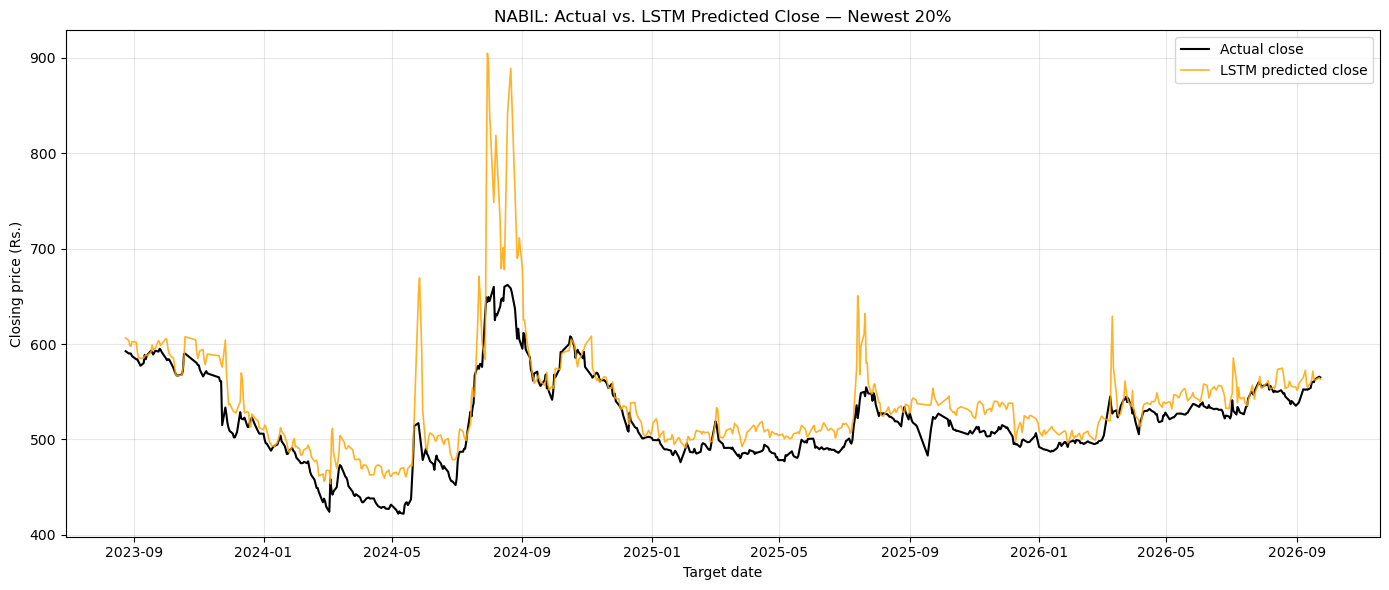

,date,actual_close,predicted_close,baseline_close
0,2023-08-24,592.5,606.263306,599.0
1,2023-08-27,590.0,603.581055,592.5
2,2023-08-28,590.1,598.456787,590.0
3,2023-08-29,590.0,597.596558,590.1
4,2023-08-30,587.3,602.528992,590.0


In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# Arrange each window from oldest session to newest.
ordered_features = []

for day in range(LOOKBACK, 0, -1):
    for parameter in parameters:
        ordered_features.append(f"{parameter}_{day}")

number_of_parameters = len(parameters)

X = samples[ordered_features].to_numpy()
X = X.reshape(
    len(samples),
    LOOKBACK,
    number_of_parameters
)

y = samples["actual_close"].to_numpy().reshape(-1, 1)

# Oldest 80% for training, newest 20% for testing.
cut = int(len(samples) * 0.8)

if cut < 100 or len(samples) - cut < 5:
    raise ValueError("Not enough examples for this train/test split.")

X_train = X[:cut]
X_test = X[cut:]

y_train = y[:cut]
y_test = y[cut:]

test_dates = samples["published_date"].iloc[cut:]

# Use the latest 20% of the training portion for validation.
validation_cut = int(len(X_train) * 0.8)

input_scaler = StandardScaler()
target_scaler = StandardScaler()

# During epoch selection, fit scalers only on fitting examples.
input_scaler.fit(
    X_train[:validation_cut].reshape(-1, number_of_parameters)
)
target_scaler.fit(y_train[:validation_cut])

def scale_windows(values):
    scaled = input_scaler.transform(
        values.reshape(-1, number_of_parameters)
    )
    return scaled.reshape(values.shape)

def build_test_model():
    new_model = Sequential([
        Input(shape=(LOOKBACK, number_of_parameters)),
        LSTM(32),
        Dense(1)
    ])

    new_model.compile(optimizer="adam", loss="mse")
    return new_model

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

test_model = build_test_model()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

print("Choosing training epochs...")

history = test_model.fit(
    scale_windows(X_train[:validation_cut]),
    target_scaler.transform(y_train[:validation_cut]),
    validation_data=(
        scale_windows(X_train[validation_cut:]),
        target_scaler.transform(y_train[validation_cut:])
    ),
    epochs=100,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop],
    verbose=0
)

best_epochs = int(np.argmin(history.history["val_loss"]) + 1)

# Refit on the entire oldest 80%, keeping test data separate.
input_scaler.fit(
    X_train.reshape(-1, number_of_parameters)
)
target_scaler.fit(y_train)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

test_model = build_test_model()

print("Training the final model...")

test_model.fit(
    scale_windows(X_train),
    target_scaler.transform(y_train),
    epochs=best_epochs,
    batch_size=32,
    shuffle=False,
    verbose=0
)

# Predict all dates in the newest 20%.
scaled_predictions = test_model.predict(
    scale_windows(X_test),
    verbose=0
)

predicted_prices = target_scaler.inverse_transform(
    scaled_predictions
).ravel()

actual_prices = y_test.ravel()

baseline_prices = samples["close_1"].iloc[cut:].to_numpy()

model_mae = mean_absolute_error(actual_prices, predicted_prices)
baseline_mae = mean_absolute_error(actual_prices, baseline_prices)

test_predictions = pd.DataFrame({
    "date": test_dates.to_numpy(),
    "actual_close": actual_prices,
    "predicted_close": predicted_prices,
    "baseline_close": baseline_prices
})

print("\nModel: LSTM")
print("Training examples:", len(X_train))
print("Test examples:", len(X_test))
print("Training epochs:", best_epochs)
print("Test dates:", test_dates.iloc[0].date(),
      "to", test_dates.iloc[-1].date())
print(f"LSTM MAE: Rs. {model_mae:.2f}")
print(f"Baseline MAE: Rs. {baseline_mae:.2f}")

# Graph the test predictions.
plt.figure(figsize=(14, 6))

plt.plot(
    test_predictions["date"],
    test_predictions["actual_close"],
    label="Actual close",
    color="black",
    linewidth=1.5
)

plt.plot(
    test_predictions["date"],
    test_predictions["predicted_close"],
    label="LSTM predicted close",
    color="orange",
    linewidth=1.2,
    alpha=0.85
)

plt.title("NABIL: Actual vs. LSTM Predicted Close — Newest 20%")
plt.xlabel("Target date")
plt.ylabel("Closing price (Rs.)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(test_predictions.head())

In [13]:
monthly_data = test_predictions.copy()

monthly_data["date"] = pd.to_datetime(monthly_data["date"])

monthly_data = monthly_data[
    monthly_data["date"].dt.year == 2026
].copy()

monthly_data["absolute_error"] = abs(
    monthly_data["actual_close"] - monthly_data["predicted_close"]
)

monthly_data["baseline_error"] = abs(
    monthly_data["actual_close"] - monthly_data["baseline_close"]
)

monthly_data["month"] = monthly_data["date"].dt.to_period("M")

monthly_errors = monthly_data.groupby("month").agg(
    days_tested=("absolute_error", "count"),
    lstm_mae=("absolute_error", "mean"),
    baseline_mae=("baseline_error", "mean")
)

# Show every month, including months without test predictions.
all_months = pd.period_range(
    "2026-01", "2026-12", freq="M"
)

monthly_errors = monthly_errors.reindex(all_months)
monthly_errors.index.name = "month"

monthly_errors["days_tested"] = (
    monthly_errors["days_tested"].fillna(0).astype(int)
)

display(monthly_errors.round(2))

,days_tested,lstm_mae,baseline_mae
month,,,
2026-01,18,14.31,2.12
2026-02,17,8.03,1.28
2026-03,18,20.19,7.08
2026-04,21,10.81,3.69
2026-05,18,16.82,1.39
2026-06,22,16.93,1.76
2026-07,23,10.49,4.21
2026-08,20,12.72,2.35
2026-09,14,8.60,2.37
